# Introduction to qim3d

**qim3d** is a Python library for **Quantitative Imaging in 3D**, developed at the [QIM Center](https://qim.dk) at DTU. It gives you generators for synthetic data, interactive visualization, filtering, segmentation and quantitative analysis, all working directly on plain NumPy arrays.

This notebook is a guided tour built around one idea: **synthetic data comes with ground truth**, so we can build a realistic problem, solve it, and *measure* how well we did.

In [1]:
import qim3d

SEED = 42   # random seed, so every run gives the same data 

In [2]:
blob = qim3d.generate.volume(
    base_shape=(128, 128, 128),
    noise_scale=0.03,
    seed=SEED,
)

print(f"Shape: {blob.shape}")
print(f"Dtype: {blob.dtype}")
print(f"Intensity range: {blob.min()} .. {blob.max()}")

Shape: (128, 128, 128)
Dtype: uint8
Intensity range: 0 .. 255


### Looking at the volume in different ways

No single view tells the whole story, so qim3d offers several. Start with a **montage of slices**:

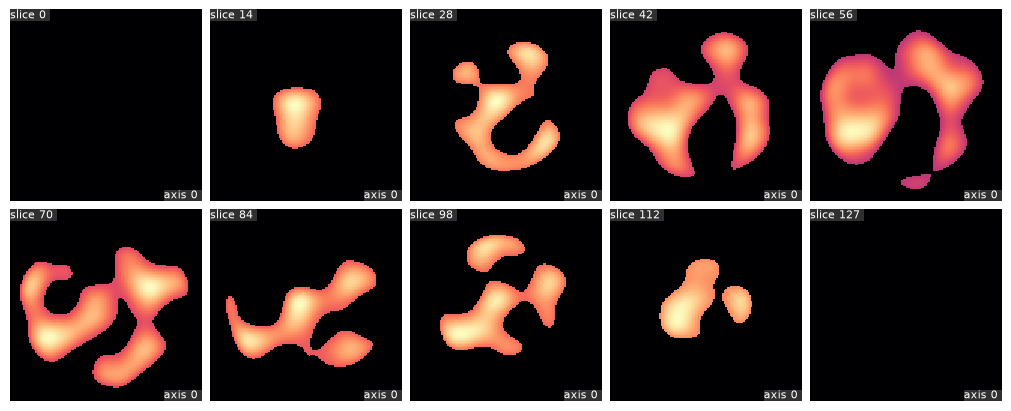

In [3]:
qim3d.viz.slices_grid(blob, n_slices=10)

The **intensity histogram** (zero-valued background voxels are ignored by default):

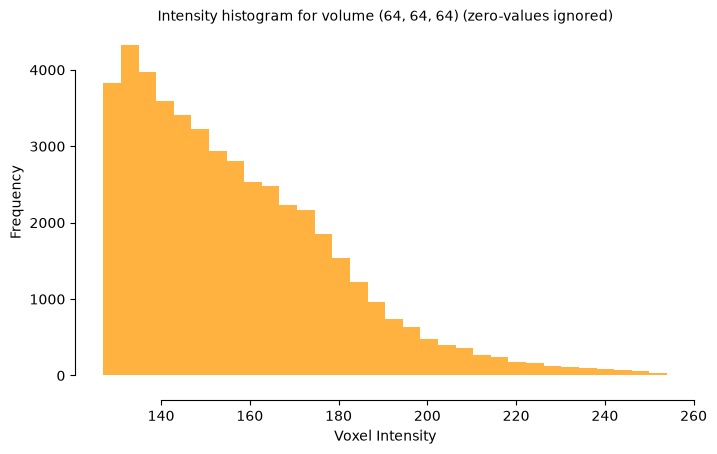

In [5]:
qim3d.viz.histogram(blob, bins=32, coarseness=2);

A hardware-accelerated **3D ray-cast rendering**. Rotate with the mouse:

In [6]:
qim3d.viz.volumetric(blob)

Output()

A **turntable animation**, handy for slides and reports (this takes a few seconds to render):

Rendering:   0%|          | 0/64 [00:00<?, ?it/s]

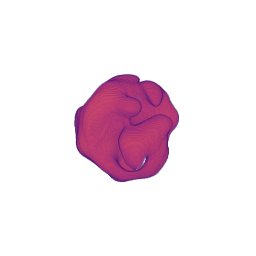

In [7]:
qim3d.viz.export_rotation('blob.gif', blob, n_frames=64, fps=12, show=True)

### Beyond blobs

`generate.volume` can also produce cylinders and tubes, and qim3d has dedicated generators for structured objects: `generate.rope` (twisted fibre bundle, which we will use in Part 6) and `generate.berry` (a raspberry-like cluster of small spheres). Here is the central slice of each:

blob


Rendering:   0%|          | 0/64 [00:00<?, ?it/s]

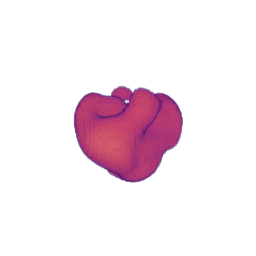

hollow blob


Rendering:   0%|          | 0/64 [00:00<?, ?it/s]

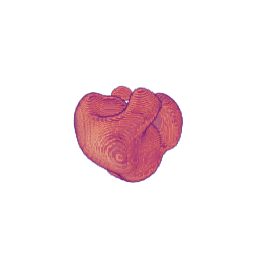

cylinder (side)


Rendering:   0%|          | 0/64 [00:00<?, ?it/s]

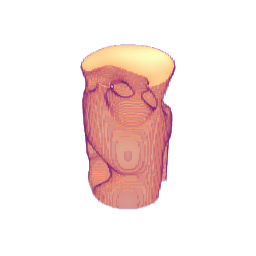

tube (side)


Rendering:   0%|          | 0/64 [00:00<?, ?it/s]

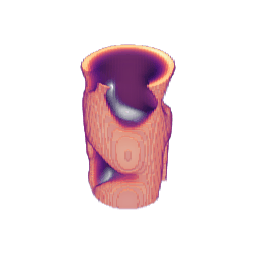

rope (end-on)


Rendering:   0%|          | 0/64 [00:00<?, ?it/s]

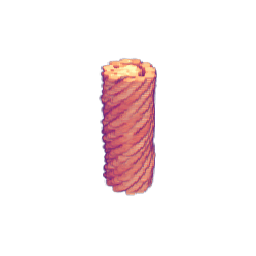

berry


Rendering:   0%|          | 0/64 [00:00<?, ?it/s]

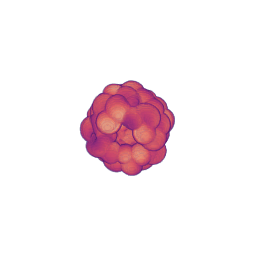

In [8]:
shape3 = (96, 96, 96)
# cylinders and tubes need a high threshold and low gamma so the shape dominates over the noise texture
tube_kw = dict(base_shape=(100, 64, 64), noise_scale=0.03, threshold=0.85, decay_rate=20, gamma=0.15, seed=SEED)

# (title, volume, which slice to show)
gallery = [
    ("blob",              qim3d.generate.volume(base_shape=shape3, noise_scale=0.03, seed=SEED),             lambda v: v[v.shape[0] // 2]),
    ("hollow blob",       qim3d.generate.volume(base_shape=shape3, noise_scale=0.03, hollow=4, seed=SEED),   lambda v: v[v.shape[0] // 2]),
    ("cylinder (side)",   qim3d.generate.volume(shape='cylinder', **tube_kw),                                lambda v: v[:, v.shape[1] // 2, :]),
    ("tube (side)",       qim3d.generate.volume(shape='tube', tube_hole_ratio=0.4, **tube_kw),               lambda v: v[:, v.shape[1] // 2, :]),
    ("rope (end-on)",     qim3d.generate.rope(shape=(96, 80, 80), seed=SEED),                                lambda v: v[v.shape[0] // 2]),
    ("berry",             qim3d.generate.berry(shape=(128, 128, 128), seed=SEED),                            lambda v: v[v.shape[0] // 2]),
]

# Show generated items

for item in gallery:
    print(item[0])
    qim3d.viz.export_rotation(f'{item[0]}.gif', item[1], n_frames=64, fps=12, show=True)
    

## Generating a synthetic dataset

`qim3d.generate.volume_collection` places many non-overlapping, randomly rotated objects inside a larger container volume and also returns a **label volume** in which every object has its own integer ID. That is exactly what you need for developing and benchmarking instance segmentation, detection or measurement methods.

We ask for 24 objects with edge lengths between 24 and 64 voxels, so the dataset contains both small and large objects.

In [9]:
collection, labels = qim3d.generate.volume_collection(
    n_volumes=24,
    collection_shape=(200, 200, 200),
    shape_range=((24, 24, 24), (64, 64, 64)),
    noise_range=(0.02, 0.04),
    seed=SEED,
)

print(f"Collection: shape {collection.shape}, dtype {collection.dtype}")
print(f"Labels:     {labels.max()} objects (IDs 1..{labels.max()}, 0 = background)")
print(f"Objects occupy {100 * (labels > 0).mean():.1f}% of the volume")

Objects placed:   0%|          | 0/24 [00:00<?, ?it/s]

Collection: shape (200, 200, 200), dtype uint8
Labels:     24 objects (IDs 1..24, 0 = background)
Objects occupy 5.1% of the volume


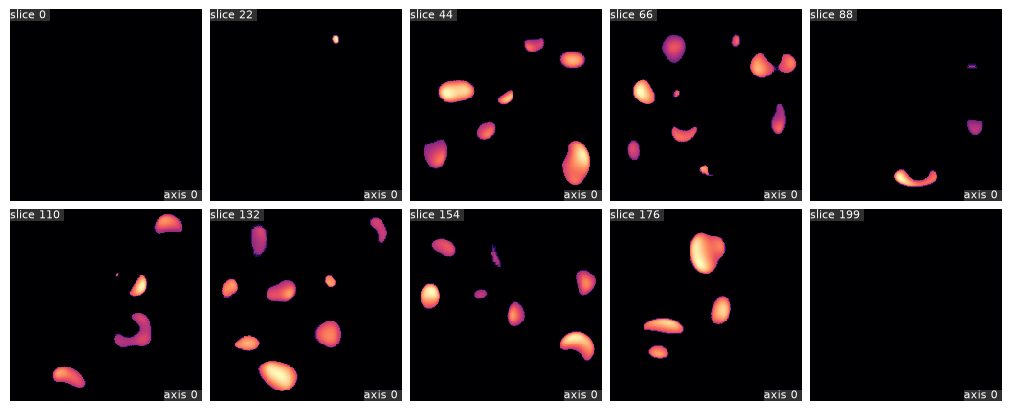

In [10]:
qim3d.viz.slices_grid(collection, n_slices=10)

In [11]:
qim3d.viz.volumetric(collection)

Output()

### Checking the labels

Here the labels come straight from the generator, but they could just as well be the output of a segmentation algorithm. `qim3d.viz.colormaps.segmentation` makes a colormap with distinct colours per label, and `qim3d.viz.overlay` lets you blend the labels over the image with an adjustable transparency.

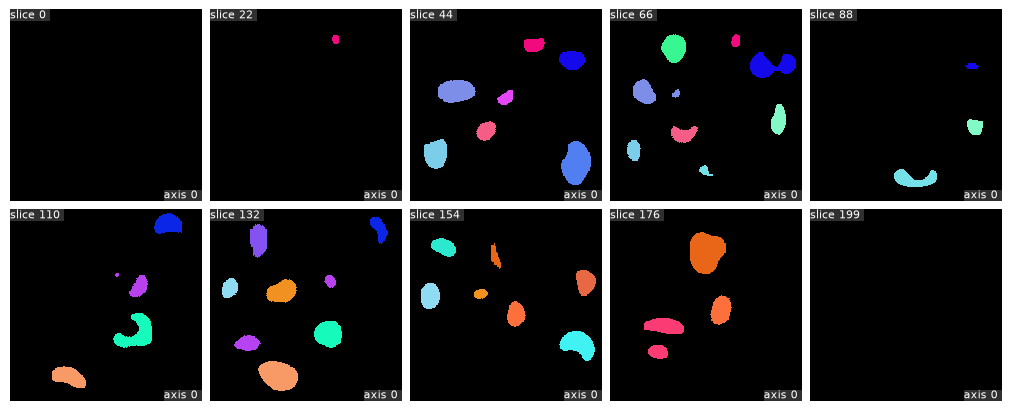

In [12]:
cmap = qim3d.viz.colormaps.segmentation(n_labels=labels.max())
qim3d.viz.slices_grid(labels, colormap=cmap, max_value=labels.max(), n_slices=10)

## From a noisy scan to a segmentation

Real scans are never this clean. Let's degrade the data and see how well we can recover the objects, using the ground truth to **score** the result.

`qim3d.generate.background` adds synthetic background noise to an existing volume. Here every voxel gets uniform random noise between 0 and 100 added to it (the result is clipped to the `uint8` range).

In [13]:
noisy = qim3d.generate.background(
    background_shape=collection.shape,
    min_noise_value=0,
    max_noise_value=100,
    generate_method='add',
    apply_method='add',
    apply_to=collection,
    seed=SEED,
)


In [14]:
# We can use the qim3d overlay functionality to compare the original volume with the noisy version
qim3d.viz.overlay(collection, noisy)

### Filtering and thresholding

In [15]:
filtered_median = qim3d.filters.median(noisy, size = 4)

In [16]:
qim3d.viz.overlay(collection, filtered_median)

In [17]:
filtered_guaussian = qim3d.filters.gaussian(filtered_median, sigma = 2)

In [18]:
qim3d.viz.overlay(collection, filtered_guaussian)

In [20]:
threshold = qim3d.operations.threshold(filtered_guaussian, method='otsu')
print(f"Otsu threshold: {threshold}")

Otsu threshold: 107.0


In [21]:
binary = filtered_guaussian > threshold

In [22]:
qim3d.viz.overlay(collection, binary, colormaps=["viridis", "gray"])

## Counting and measuring objects

`qim3d.segmentation.connected_components` labels every group of touching foreground voxels. The returned object holds the label volume and the size of every component (index 0 is the background).

In [23]:
cc = qim3d.segmentation.connected_components(binary)

sizes = cc.sizes[1:] # drop the background entry, as we only want to count objects
print(f"{len(sizes)} connected components found; the ground truth has {labels.max()} objects")

24 connected components found; the ground truth has 24 objects


## Structure tensor: which way do the structures point?

The **structure tensor** measures the local orientation of structures from image gradients. For every voxel it gives three eigenvalues and eigenvectors. For fibre-like structures, the eigenvector belonging to the **smallest** eigenvalue is the direction of least intensity change, i.e. **along the fibre**.

Two scales control the analysis:
- `sigma` (noise scale): Gaussian smoothing before taking gradients. Structures smaller than this are suppressed.
- `rho` (integration scale): the neighbourhood over which orientations are averaged. Larger gives smoother fields but blurs details.

As test object we use `qim3d.generate.rope`: 18 threads twisted around a common axis. The orientation is *not* simply along the rope; it should tilt more and more as we move away from the centre, like the threads in a real rope.

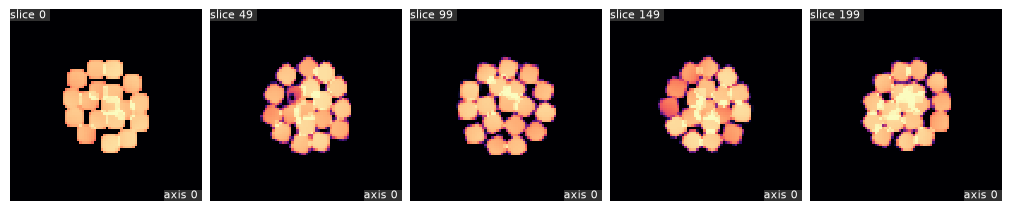

In [24]:
rope, thread_labels = qim3d.generate.rope(
    shape=(200, 80, 80),        # (length, diameter, diameter): the rope runs along axis 0
    num_threads=18,
    twist_rate=2.0,
    return_labels=True,
    seed=SEED,
)

# cross-sections of the rope (slices along its axis); the threads are the bright blobs
qim3d.viz.slices_grid(rope, slice_axis=0, n_slices=5, image_size=2)

In [25]:
qim3d.viz.volumetric(rope)

Output()

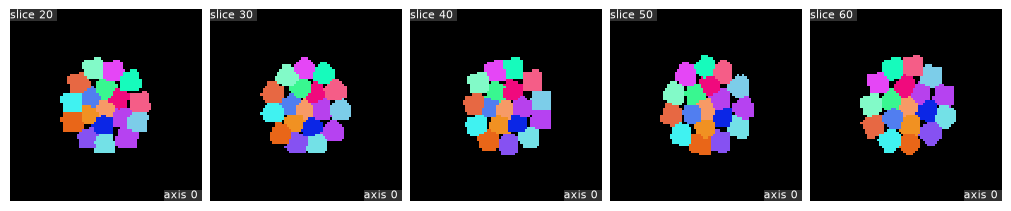

In [26]:
thread_cmap = qim3d.viz.colormaps.segmentation(n_labels=thread_labels.max())
qim3d.viz.slices_grid(thread_labels, slice_axis=0, slice_positions=[20, 30, 40, 50, 60],
                      colormap=thread_cmap, max_value=thread_labels.max())

### Computing the structure tensor

In [27]:
val, vec = qim3d.processing.structure_tensor(rope, sigma=1.0, rho=6.0)

print("eigenvalues  val:", val.shape, "(sorted ascending along axis 0)")
print("orientation  vec:", vec.shape, "(unit vector along the fibre at every voxel)")

Computing eigenvalues and eigenvectors of the structure tensor, full = False
eigenvalues  val: (3, 200, 80, 80) (sorted ascending along axis 0)
orientation  vec: (3, 200, 80, 80) (unit vector along the fibre at every voxel)


> **Component order.** Checking this against synthetic fibres with a known direction shows that the three components of `vec` are ordered **(x, y, z)**, i.e. `vec[2]` is the component along array axis 0 (z), and `vec[0]` along axis 2 (x). The docstring says (z, y, x), so double-check this if you combine `vec` with your own code. `qim3d.viz.vectors` uses the same (x, y, z) convention.

The rope runs along z (axis 0), so the angle between the local fibre direction and the rope axis is `arccos(|vec[2]|)`. A voxel on a perfectly straight, axis-aligned fibre would give 0°.

In [28]:
qim3d.viz.vectors(rope, vec, axis=0)

In [29]:
qim3d.viz.vectors(rope, vec, axis=1)

Adjusting grid size to 8 as it is out of bounds.
